In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import pandas as pd
import tensorflow as tf
import numpy as np
import random

# Fixar sementes para resultados reproduzíveis
tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

Treino = pd.read_csv('fresadera_dataset.csv')
Treino

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [ ]:
Treino.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [ ]:
Treino.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [ ]:
Treino['Type'].value_counts()

,count
Type,
L,6000
M,2997
H,1003


In [ ]:
Treino.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [ ]:
# Verificar linhas duplicadas
print(f"Linhas duplicadas: {Treino.duplicated().sum()}")

# Verificar se o Product ID é realmente único
print(f"IDs únicos: {Treino['Product ID'].nunique()} em {len(Treino)} linhas")

Linhas duplicadas: 0
IDs únicos: 10000 em 10000 linhas


Tratamento

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Carregar dados
Treino = pd.read_csv('fresadera_dataset.csv')

# Remove apenas UDI e Product ID
drop_cols = ['UDI', 'Product ID']
X = Treino.drop(columns=drop_cols + ['Torque [Nm]'])
y = Treino['Torque [Nm]']

# Preprocessing para a coluna 'Type' (OneHotEncoding)
categorical_features = ['Type']
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(), categorical_features)
    ])

# Divisão Treino e Teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Aplicar transformações
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

modelos = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest": RandomForestRegressor(n_estimators=100),
    "XGBoost": XGBRegressor(),
    "KNN": KNeighborsRegressor(),
    "SVR": SVR()
}

results = []

for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    preds = modelo.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)

    results.append({"Modelo": nome, "MAE": mae, "RMSE": rmse, "R2": r2})

df_results = pd.DataFrame(results)
print(df_results)

              Modelo       MAE      RMSE        R2
0  Linear Regression  3.423870  4.399692  0.803590
1              Ridge  3.423984  4.399731  0.803586
2      Decision Tree  4.035550  5.231606  0.722291
3      Random Forest  2.999090  3.892869  0.846234
4            XGBoost  3.060166  3.972746  0.839859
5                KNN  3.330490  4.347962  0.808181
6                SVR  3.090843  4.270338  0.814969


Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 755.3132 - mae: 21.6599 - val_loss: 36.2366 - val_mae: 4.4819
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 25.9750 - mae: 3.8412 - val_loss: 20.1490 - val_mae: 3.5034
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 17.4156 - mae: 3.2428 - val_loss: 16.5153 - val_mae: 3.1751
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 15.4289 - mae: 3.0448 - val_loss: 15.2092 - val_mae: 3.0838
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 14.8870 - mae: 2.9888 - val_loss: 14.6367 - val_mae: 2.9903
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 14.5285 - mae: 2.9469 - val_loss: 14.7249 - val_mae: 3.0025
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.4201 - mae: 2.9360 - val_loss: 14.2963 - val_mae: 2.9204
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.1621 - mae: 2.9098 - val_loss: 14.0044 - val_mae: 2.9145
Epoch 9/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1

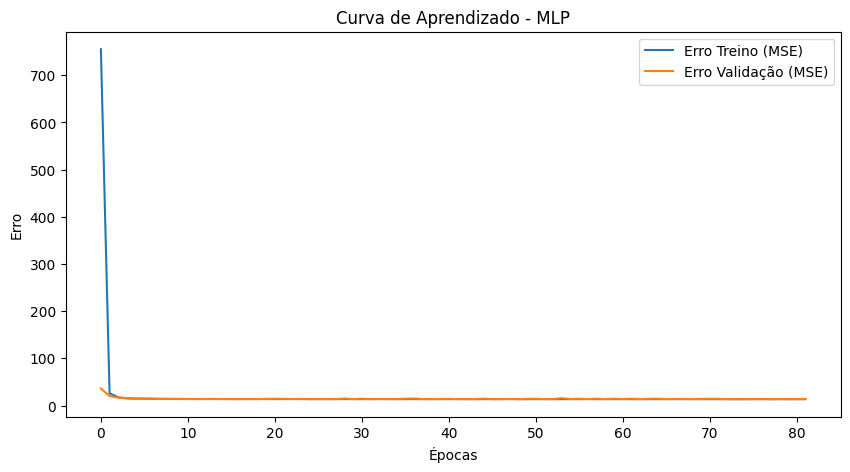

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


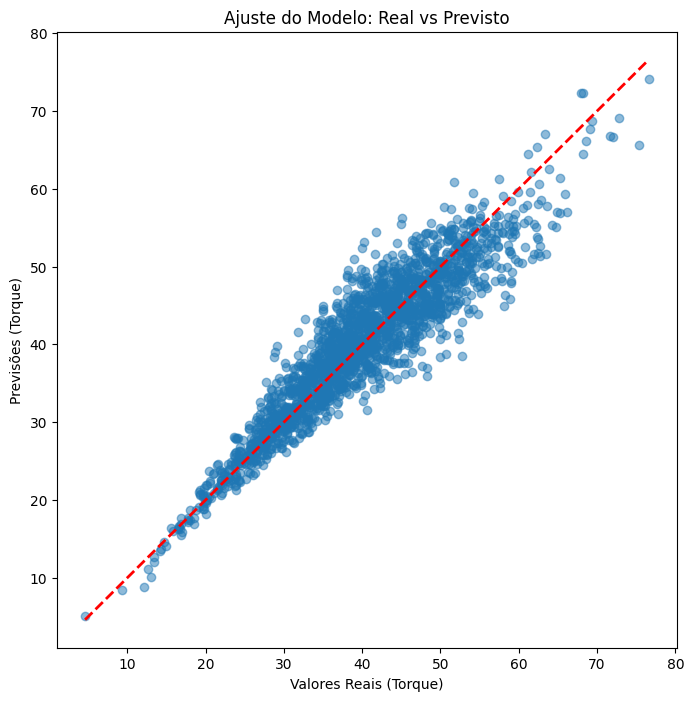

Resultados da MLP (Ativação: ReLu, Otimizador: Adam):
MAE: 2.8965
RMSE: 3.7892
R2: 0.8543


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

def criar_mlp(input_shape, activation='relu', optimizer='adam'):
    model = models.Sequential([
        layers.Dense(64, activation=activation, input_shape=(input_shape,)),
        layers.Dense(32, activation=activation),
        layers.Dense(16, activation=activation),
        layers.Dense(1)
    ])

    # Configuração customizada dos otimizadores para evitar NaNs
    if optimizer == 'adam':
        opt = tf.keras.optimizers.Adam(learning_rate=0.001)
    else:
        opt = tf.keras.optimizers.SGD(learning_rate=0.001, clipvalue=1.0)

    model.compile(optimizer=opt, loss='mse', metrics=['mae'])
    return model

# Early Stopping
monitor = callbacks.EarlyStopping(monitor='val_loss', patience=50,
                                 restore_best_weights=True, verbose=1)

# Exemplo de Treino: ReLU + Adam
mlp_model = criar_mlp(X_train.shape[1], activation='relu', optimizer='adam')

history = mlp_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[monitor],
    verbose=1
)

# Gráfico de Curva de Aprendizado (Loss)
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Erro Treino (MSE)')
plt.plot(history.history['val_loss'], label='Erro Validação (MSE)')
plt.title('Curva de Aprendizado - MLP')
plt.xlabel('Épocas')
plt.ylabel('Erro')
plt.legend()
plt.show()

# Gráfico Real vs Previsto
y_pred_mlp = mlp_model.predict(X_test).flatten()
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_mlp, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Valores Reais (Torque)')
plt.ylabel('Previsões (Torque)')
plt.title('Ajuste do Modelo: Real vs Previsto')
plt.show()

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Cálculo das métricas para a MLP atual
mae_mlp = mean_absolute_error(y_test, y_pred_mlp)
rmse_mlp = np.sqrt(mean_squared_error(y_test, y_pred_mlp))
r2_mlp = r2_score(y_test, y_pred_mlp)

print(f"Resultados da MLP (Ativação: ReLu, Otimizador: Adam):")
print(f"MAE: {mae_mlp:.4f}")
print(f"RMSE: {rmse_mlp:.4f}")
print(f"R2: {r2_mlp:.4f}")

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 1342.2344 - mae: 35.1781 - val_loss: 1162.2780 - val_mae: 32.6034
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1028.3419 - mae: 30.4627 - val_loss: 944.4177 - val_mae: 29.0742
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 836.7558 - mae: 27.1565 - val_loss: 770.4776 - val_mae: 25.9227
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 680.5699 - mae: 24.1398 - val_loss: 626.9931 - val_mae: 23.0369
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 551.9263 - mae: 21.3659 - val_loss: 508.6830 - val_mae: 20.3897
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 446.4922 - mae: 18.8544 - val_loss: 411.8168 - val_mae: 17.9902
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 360.5044 - mae: 16.5835 - val_loss: 332.3536 - val_mae: 15.7800
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 288.9731 - mae: 14.3815 - val_loss: 266.7681 - val_mae: 13.6465
Epoch 9/1

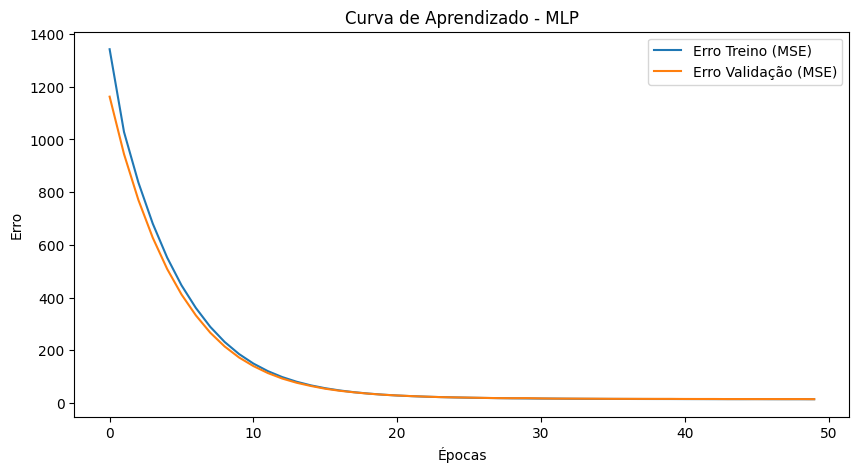

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


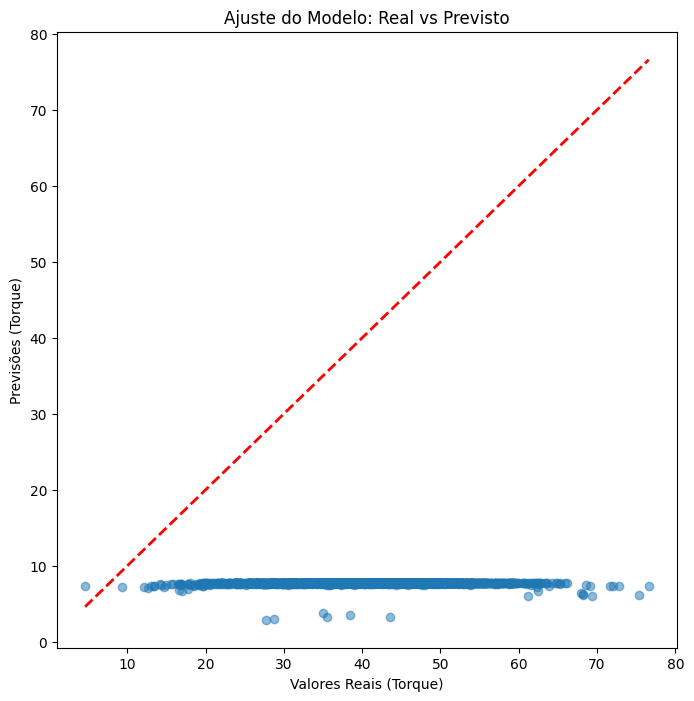

Resultados da MLP (Ativação: Tanh, Otimizador: Adam):
MAE: 32.2352
RMSE: 33.7259
R2: -10.5411


In [ ]:

mlp_model = criar_mlp(X_train.shape[1], activation='tanh', optimizer='adam')

history = mlp_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[monitor],
    verbose=1
)

# Gráfico de Curva de Aprendizado (Loss)
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Erro Treino (MSE)')
plt.plot(history.history['val_loss'], label='Erro Validação (MSE)')
plt.title('Curva de Aprendizado - MLP')
plt.xlabel('Épocas')
plt.ylabel('Erro')
plt.legend()
plt.show()

# Gráfico Real vs Previsto
y_pred_mlp = mlp_model.predict(X_test).flatten()
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_mlp, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Valores Reais (Torque)')
plt.ylabel('Previsões (Torque)')
plt.title('Ajuste do Modelo: Real vs Previsto')
plt.show()

# Cálculo das métricas para a MLP atual
mae_mlp = mean_absolute_error(y_test, y_pred_mlp)
rmse_mlp = np.sqrt(mean_squared_error(y_test, y_pred_mlp))
r2_mlp = r2_score(y_test, y_pred_mlp)

print(f"Resultados da MLP (Ativação: Tanh, Otimizador: Adam):")
print(f"MAE: {mae_mlp:.4f}")
print(f"RMSE: {rmse_mlp:.4f}")
print(f"R2: {r2_mlp:.4f}")

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 722.2932 - mae: 21.5386 - val_loss: 33.3907 - val_mae: 4.4476
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 22.7554 - mae: 3.6438 - val_loss: 18.5763 - val_mae: 3.3455
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 16.4805 - mae: 3.1354 - val_loss: 15.1592 - val_mae: 3.0834
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 15.2046 - mae: 3.0204 - val_loss: 14.4275 - val_mae: 2.9884
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 14.7360 - mae: 2.9660 - val_loss: 13.8619 - val_mae: 2.9290
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 14.5641 - mae: 2.9440 - val_loss: 13.9684 - val_mae: 2.9423
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 14.4373 - mae: 2.9261 - val_loss: 14.6024 - val_mae: 2.9434
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 14.3370 - mae: 2.9162 - val_loss: 13.7451 - val_mae: 2.9087
Epoch 9/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1

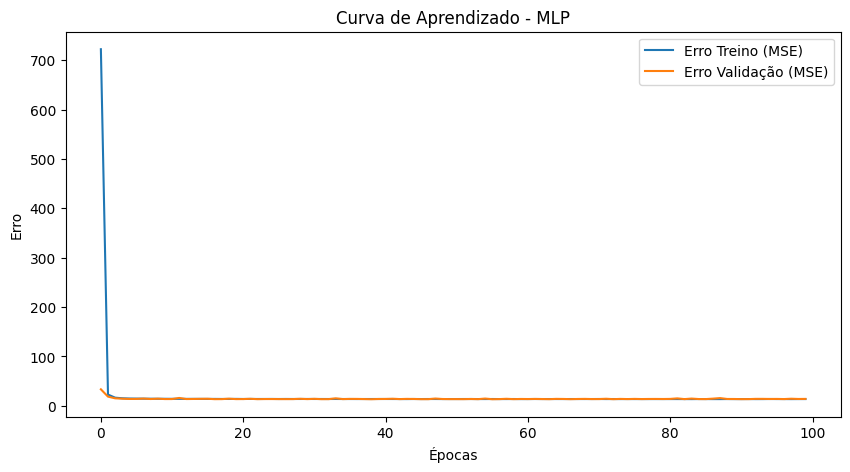

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


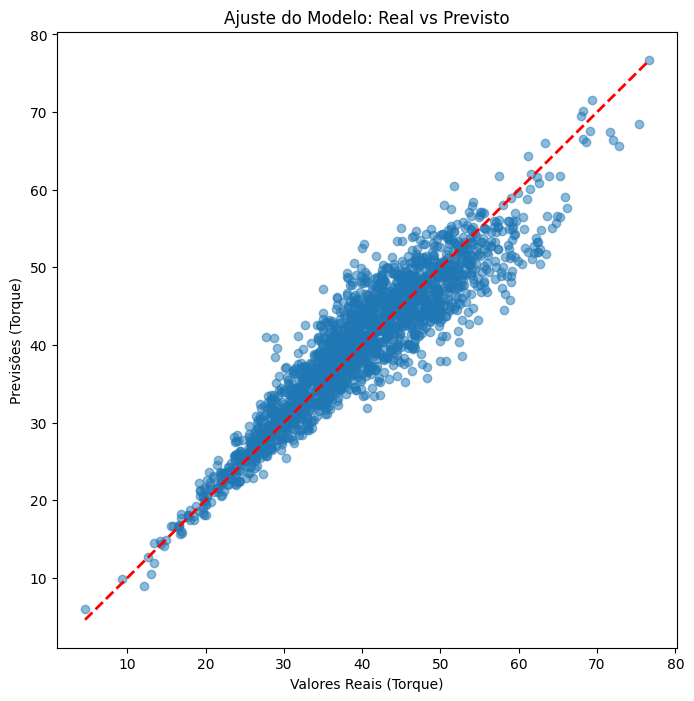

Resultados da MLP (Ativação: ReLu, Otimizador: SGD):
MAE: 2.8959
RMSE: 3.8026
R2: 0.8533


In [ ]:
mlp_model = criar_mlp(X_train.shape[1], activation='relu', optimizer='sgd')

history = mlp_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[monitor],
    verbose=1
)

# Gráfico de Curva de Aprendizado
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Erro Treino (MSE)')
plt.plot(history.history['val_loss'], label='Erro Validação (MSE)')
plt.title('Curva de Aprendizado - MLP')
plt.xlabel('Épocas')
plt.ylabel('Erro')
plt.legend()
plt.show()

# Gráfico Real vs Previsto
y_pred_mlp = mlp_model.predict(X_test).flatten()
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_mlp, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Valores Reais (Torque)')
plt.ylabel('Previsões (Torque)')
plt.title('Ajuste do Modelo: Real vs Previsto')
plt.show()

# Cálculo das métricas para a MLP atual
mae_mlp = mean_absolute_error(y_test, y_pred_mlp)
rmse_mlp = np.sqrt(mean_squared_error(y_test, y_pred_mlp))
r2_mlp = r2_score(y_test, y_pred_mlp)

print(f"Resultados da MLP (Ativação: ReLu, Otimizador: SGD):")
print(f"MAE: {mae_mlp:.4f}")
print(f"RMSE: {rmse_mlp:.4f}")
print(f"R2: {r2_mlp:.4f}")

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1316.3486 - mae: 34.8147 - val_loss: 1149.6703 - val_mae: 32.4107
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1021.9763 - mae: 30.3598 - val_loss: 939.0942 - val_mae: 28.9819
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 826.9066 - mae: 26.9638 - val_loss: 753.3409 - val_mae: 25.5915
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 655.1261 - mae: 23.6031 - val_loss: 590.9019 - val_mae: 22.2586
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 506.1659 - mae: 20.2975 - val_loss: 451.4560 - val_mae: 18.9829
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 379.9159 - mae: 17.0991 - val_loss: 335.3140 - val_mae: 15.8898
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 278.2403 - mae: 14.1652 - val_loss: 243.6251 - val_mae: 13.0655
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 198.2548 - mae: 11.5478 - val_loss: 170.1179 - val_mae: 10.5664
Epoch 9/1

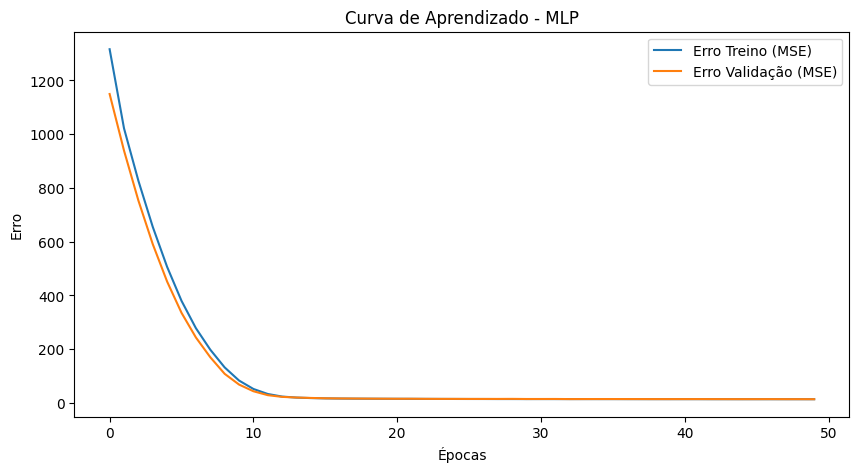

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


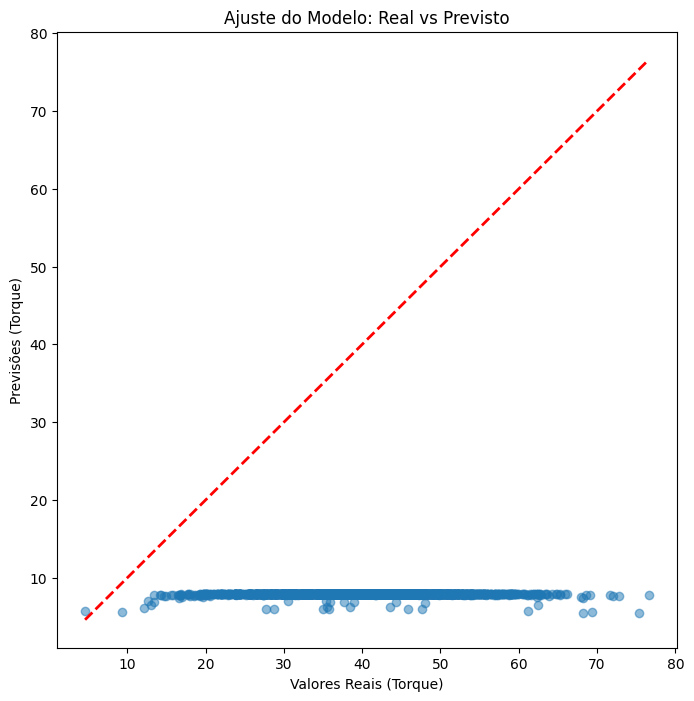

Resultados da MLP (Ativação: Tanh, Otimizador: SGD):
MAE: 32.0365
RMSE: 33.5376
R2: -10.4125


In [ ]:
mlp_model = criar_mlp(X_train.shape[1], activation='tanh', optimizer='sgd')

history = mlp_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[monitor],
    verbose=1
)

# Gráfico de Curva de Aprendizado (Loss)
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Erro Treino (MSE)')
plt.plot(history.history['val_loss'], label='Erro Validação (MSE)')
plt.title('Curva de Aprendizado - MLP')
plt.xlabel('Épocas')
plt.ylabel('Erro')
plt.legend()
plt.show()

# Gráfico Real vs Previsto
y_pred_mlp = mlp_model.predict(X_test).flatten()
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_mlp, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Valores Reais (Torque)')
plt.ylabel('Previsões (Torque)')
plt.title('Ajuste do Modelo: Real vs Previsto')
plt.show()


mae_mlp = mean_absolute_error(y_test, y_pred_mlp)
rmse_mlp = np.sqrt(mean_squared_error(y_test, y_pred_mlp))
r2_mlp = r2_score(y_test, y_pred_mlp)

print(f"Resultados da MLP (Ativação: Tanh, Otimizador: SGD):")
print(f"MAE: {mae_mlp:.4f}")
print(f"RMSE: {rmse_mlp:.4f}")
print(f"R2: {r2_mlp:.4f}")

In [ ]:
def construir_mlp_dinamica(input_shape, camadas=[64, 32], ativação='relu', otimizador='adam', lr=0.001, cv=1.0):
    model = models.Sequential()
    model.add(layers.Input(shape=(input_shape,)))
    for n in camadas:
        model.add(layers.Dense(n, activation=act))
    model.add(layers.Dense(1))

    if otimizador == 'adam':
        opt = tf.keras.optimizers.Adam(learning_rate=lr)
    else:
        opt = tf.keras.optimizers.SGD(learning_rate=lr, clipvalue=cv)

    model.compile(optimizer=opt, loss='mse', metrics=['mae'])
    return model

In [ ]:
arquiteturas = [
    [8],
    [16],
    [32,16],
    [64, 32,16],
    [128, 64, 32,16],
    [256, 128, 64, 32,16]
]

ativacoes = ['relu', 'tanh']
otimizadores = ['adam', 'sgd']

resultados_completos = []

for camadas in arquiteturas:
    for act in ativacoes:
        for opt in otimizadores:
            nome_teste = f"Arq_{camadas}_Act_{act}_Opt_{opt}"
            print(f"Executando: {nome_teste}")

            # 1. Construir
            modelo = construir_mlp_dinamica(X_train.shape[1], camadas=camadas, ativação=act, otimizador=opt)

            # 2. Treinar
            history = modelo.fit(
                X_train, y_train,
                validation_split=0.2,
                epochs=200,
                batch_size=32,
                callbacks=[monitor],
                verbose=0
            )

            # 3. Gerar Previsões
            y_pred = modelo.predict(X_test).flatten()
            y_pred_train = modelo.predict(X_train).flatten()

            # 4. VERIFICAÇÃO DE NAN
            if np.isnan(y_pred).any() or np.isnan(y_pred_train).any():
                print(f"--- AVISO: {nome_teste} gerou NaNs e será ignorado ---")
                r2, mae, rmse, mae_train, diff = np.nan, np.nan, np.nan, np.nan, np.nan
            else:
                r2 = r2_score(y_test, y_pred)
                mae = mean_absolute_error(y_test, y_pred)
                rmse = np.sqrt(mean_squared_error(y_test, y_pred))
                mae_train = mean_absolute_error(y_train, y_pred_train)
                diff = mae - mae_train

            # 5. Salvar
            resultados_completos.append({
                'Arquitetura': str(camadas),
                'Ativação': act,
                'Otimizador': opt,
                'R2': r2,
                'MAE_Teste': mae,
                'MAE_Treino': mae_train,
                'Diff_MAE': diff,
                'RMSE': rmse,
                'Epocas': len(history.history['loss'])
            })


df_final = pd.DataFrame(resultados_completos)
print(df_final.sort_values(by='R2', ascending=False).head(10))

Executando: Arq_[8]_Act_relu_Opt_adam
Epoch 50: early stopping
Restoring model weights from the end of the best epoch: 1.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Executando: Arq_[8]_Act_relu_Opt_sgd
Epoch 50: early stopping
Restoring model weights from the end of the best epoch: 1.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Executando: Arq_[8]_Act_tanh_Opt_adam
Epoch 50: early stopping
Restoring model weights from the end of the best epoch: 1.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Executando: Arq_[8]_Act_tanh_Opt_sgd
Epoch 50: early stopping
Restoring model weights from the end of the best epoch: 1.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Executando: Arq_[16]_Act_relu_Opt_adam
Epoch 50: early stopping
Restoring model weights from the end of the best epoch: 1.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 0

In [ ]:
def construir_mlp_expert(input_shape, camadas=[64, 32, 16], act='relu', opt_name='adam', lr=0.001, clip=1.0, dropout_rate=0.0):
    model = models.Sequential()
    model.add(layers.Input(shape=(input_shape,)))

    for n in camadas:
        model.add(layers.Dense(n, activation=act))
        if dropout_rate > 0:
            model.add(layers.Dropout(dropout_rate))

    model.add(layers.Dense(1))

    if opt_name == 'adam':
        opt = tf.keras.optimizers.Adam(learning_rate=lr)
    else:
        opt = tf.keras.optimizers.SGD(learning_rate=lr, clipvalue=clip)

    model.compile(optimizer=opt, loss='mse', metrics=['mae'])
    return model

In [ ]:
# Listas de Hiperparâmetros
arquiteturas = [[16],[32,16], [64, 32, 16], [256, 128, 64, 32, 16]]
lrs = [0.01, 0.001, 0.0001]
clips = [0.5, 1.0]
batches = [16, 32, 64]
dropouts = [0.0, 0.2]
ativacoes = ['relu', 'tanh']
otimizadores = ['adam', 'sgd']

resultados_completos = []

# Loop
for camadas in arquiteturas:
    for act in ativacoes:
        for opt in otimizadores:
            for lr in lrs:
                for cv in clips:
                    for bs in batches:
                        for dr in dropouts:
                            nome_teste = f"Arq:{camadas}|Act:{act}|Opt:{opt}|LR:{lr}|BS:{bs}|DR:{dr}"
                            print(f"Rodando: {nome_teste}")

                            # 1. Construir
                            modelo = construir_mlp_expert(X_train.shape[1], camadas, act, opt, lr, cv, dr)

                            # 2. Treinar
                            history = modelo.fit(
                                X_train, y_train,
                                validation_split=0.2,
                                epochs=200,
                                batch_size=bs,
                                callbacks=[monitor],
                                verbose=0
                            )

                            # 3. Previsões e Métricas
                            y_pred = modelo.predict(X_test).flatten()
                            y_pred_train = modelo.predict(X_train).flatten()

                            if np.isnan(y_pred).any():
                                metrics = [np.nan] * 5
                            else:
                                metrics = [
                                    r2_score(y_test, y_pred),
                                    mean_absolute_error(y_test, y_pred),
                                    mean_absolute_error(y_train, y_pred_train),
                                    np.sqrt(mean_squared_error(y_test, y_pred)),
                                    len(history.history['loss'])
                                ]

                            # 4. Salvar tudo
                            resultados_completos.append({
                                'Arquitetura': str(camadas), 'Ativação': act, 'Otimizador': opt,
                                'LR': lr, 'Batch': bs, 'Dropout': dr, 'Clip': cv,
                                'R2': metrics[0], 'MAE_Teste': metrics[1], 'MAE_Treino': metrics[2],
                                'Diff_MAE': metrics[1] - metrics[2] if not np.isnan(metrics[1]) else np.nan,
                                'RMSE': metrics[3], 'Epocas': metrics[4]
                            })

df_grid = pd.DataFrame(resultados_completos)

Rodando: Arq:[16]|Act:relu|Opt:adam|LR:0.01|BS:16|DR:0.0
Epoch 94: early stopping
Restoring model weights from the end of the best epoch: 44.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Rodando: Arq:[16]|Act:relu|Opt:adam|LR:0.01|BS:16|DR:0.2
Epoch 50: early stopping
Restoring model weights from the end of the best epoch: 1.
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Rodando: Arq:[16]|Act:relu|Opt:adam|LR:0.01|BS:32|DR:0.0
Epoch 102: early stopping
Restoring model weights from the end of the best epoch: 52.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Rodando: Arq:[16]|Act:relu|Opt:adam|LR:0.01|BS:32|DR:0.2
Epoch 50: early stopping
Restoring model weights from the end of the best epoch: 1.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Rodando: Arq:[16]|Act:relu|Opt:adam|LR:0.01|BS:64|DR:0.0
Epoch 50: early stopping
Restoring model weights f

In [ ]:
df_grid

,Arquitetura,Ativação,Otimizador,LR,Batch,Dropout,Clip,R2,MAE_Teste,MAE_Treino,Diff_MAE,RMSE,Epocas
0,[16],relu,adam,0.0100,16,0.0,0.5,0.851332,2.913127,2.821499,0.091628,3.827798,94
1,[16],relu,adam,0.0100,16,0.2,0.5,0.809221,3.262149,3.209065,0.053083,4.336163,50
2,[16],relu,adam,0.0100,32,0.0,0.5,0.852946,2.888473,2.824957,0.063515,3.806967,102
3,[16],relu,adam,0.0100,32,0.2,0.5,0.681979,3.902489,3.944047,-0.041557,5.598457,50
4,[16],relu,adam,0.0100,64,0.0,0.5,0.667589,4.421412,4.331183,0.090229,5.723711,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...
571,"[256, 128, 64, 32, 16]",tanh,sgd,0.0001,16,0.2,1.0,-13.129723,35.968901,36.072992,-0.104090,37.317022,50
572,"[256, 128, 64, 32, 16]",tanh,sgd,0.0001,32,0.0,1.0,-13.373426,36.263166,36.395372,-0.132206,37.637459,50
573,"[256, 128, 64, 32, 16]",tanh,sgd,0.0001,32,0.2,1.0,-13.497876,36.460974,36.553664,-0.092690,37.800047,50
574,"[256, 128, 64, 32, 16]",tanh,sgd,0.0001,64,0.0,1.0,-14.399550,37.716995,37.827707,-0.110712,38.957778,50


In [ ]:
# Ordenar pelo maior R2
top_10 = df_grid.sort_values(by='R2', ascending=False).head(10)
print(top_10[['Arquitetura', 'Ativação', 'Otimizador', 'LR', 'R2', 'Diff_MAE','Batch',	'Dropout',	'Clip',	'MAE_Teste',	'MAE_Treino',	'RMSE',	'Epocas']])

                Arquitetura Ativação Otimizador     LR        R2  Diff_MAE  \
38                     [16]     relu        sgd  0.010  0.854394  0.060316   
2                      [16]     relu       adam  0.010  0.852946  0.063515   
0                      [16]     relu       adam  0.010  0.851332  0.091628   
444  [256, 128, 64, 32, 16]     relu       adam  0.001  0.839227  0.085756   
146                [32, 16]     relu       adam  0.010  0.838075  0.017867   
152                [32, 16]     relu       adam  0.010  0.837877  0.048765   
290            [64, 32, 16]     relu       adam  0.010  0.835172  0.089149   
6                      [16]     relu       adam  0.010  0.833519 -0.000136   
442  [256, 128, 64, 32, 16]     relu       adam  0.010  0.832832  0.069322   
144                [32, 16]     relu       adam  0.010  0.832468  0.075548   

     Batch  Dropout  Clip  MAE_Teste  MAE_Treino      RMSE  Epocas  
38      32      0.0   0.5   2.879424    2.819108  3.788177     100  
2  

In [ ]:
# Listas de Hiperparâmetros
arquiteturas = [[2],[4], [8], [16],[16, 8]]
lrs = [0.01, 0.001, 0.0001]
clips = [0.5, 1.0]
batches = [16, 32]
dropouts = [0.0]
ativacoes = ['relu']
otimizadores = ['adam', 'sgd']

resultados_completos = []

# Loop
for camadas in arquiteturas:
    for act in ativacoes:
        for opt in otimizadores:
            for lr in lrs:
                for cv in clips:
                    for bs in batches:
                        for dr in dropouts:
                            nome_teste = f"Arq:{camadas}|Act:{act}|Opt:{opt}|LR:{lr}|BS:{bs}|DR:{dr}"
                            print(f"Rodando: {nome_teste}")

                            # 1. Construir
                            modelo = construir_mlp_expert(X_train.shape[1], camadas, act, opt, lr, cv, dr)

                            # 2. Treinar (Ajustado com Batch Size variável)
                            history = modelo.fit(
                                X_train, y_train,
                                validation_split=0.2,
                                epochs=200, # Aumentado para dar tempo ao SGD
                                batch_size=bs, # Variável do loop
                                callbacks=[monitor],
                                verbose=0
                            )

                            # 3. Previsões e Métricas
                            y_pred = modelo.predict(X_test).flatten()
                            y_pred_train = modelo.predict(X_train).flatten()

                            if np.isnan(y_pred).any():
                                metrics = [np.nan] * 5
                            else:
                                metrics = [
                                    r2_score(y_test, y_pred),
                                    mean_absolute_error(y_test, y_pred),
                                    mean_absolute_error(y_train, y_pred_train),
                                    np.sqrt(mean_squared_error(y_test, y_pred)),
                                    len(history.history['loss'])
                                ]

                            # 4. Salvar tudo
                            resultados_completos.append({
                                'Arquitetura': str(camadas), 'Ativação': act, 'Otimizador': opt,
                                'LR': lr, 'Batch': bs, 'Dropout': dr, 'Clip': cv,
                                'R2': metrics[0], 'MAE_Teste': metrics[1], 'MAE_Treino': metrics[2],
                                'Diff_MAE': metrics[1] - metrics[2] if not np.isnan(metrics[1]) else np.nan,
                                'RMSE': metrics[3], 'Epocas': metrics[4]
                            })

df_grid2 = pd.DataFrame(resultados_completos)

Rodando: Arq:[2]|Act:relu|Opt:adam|LR:0.01|BS:16|DR:0.0
Epoch 50: early stopping
Restoring model weights from the end of the best epoch: 1.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Rodando: Arq:[2]|Act:relu|Opt:adam|LR:0.01|BS:32|DR:0.0
Epoch 50: early stopping
Restoring model weights from the end of the best epoch: 1.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Rodando: Arq:[2]|Act:relu|Opt:adam|LR:0.01|BS:16|DR:0.0
Epoch 50: early stopping
Restoring model weights from the end of the best epoch: 1.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Rodando: Arq:[2]|Act:relu|Opt:adam|LR:0.01|BS:32|DR:0.0
Epoch 50: early stopping
Restoring model weights from the end of the best epoch: 1.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Rodando: Arq:[2]|Act:relu|Opt:adam|LR:0.001|BS:16|DR:0.0
Epoch 50: early stopping
Restoring model weights from the end o

In [ ]:
df_grid2

,Arquitetura,Ativação,Otimizador,LR,Batch,Dropout,Clip,R2,MAE_Teste,MAE_Treino,Diff_MAE,RMSE,Epocas
0,[2],relu,adam,0.0100,16,0.0,0.5,0.453124,4.276113,4.319516,-0.043403,7.341500,50
1,[2],relu,adam,0.0100,32,0.0,0.5,-0.443782,7.729619,7.822165,-0.092546,11.928641,50
2,[2],relu,adam,0.0100,16,0.0,1.0,0.467240,3.853708,3.777034,0.076674,7.246128,50
3,[2],relu,adam,0.0100,32,0.0,1.0,-5.698895,23.951636,23.855390,0.096246,25.694592,50
4,[2],relu,adam,0.0010,16,0.0,0.5,-15.080351,38.695771,38.796181,-0.100410,39.809610,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,"[16, 8]",relu,sgd,0.0010,32,0.0,1.0,-13.404327,36.523419,36.617434,-0.094015,37.677896,50
116,"[16, 8]",relu,sgd,0.0001,16,0.0,0.5,-15.783578,39.412420,39.529504,-0.117085,40.670773,50
117,"[16, 8]",relu,sgd,0.0001,32,0.0,0.5,-15.652537,39.266403,39.336222,-0.069818,40.511689,50
118,"[16, 8]",relu,sgd,0.0001,16,0.0,1.0,-15.179965,38.690087,38.784271,-0.094183,39.932725,50


In [ ]:
top_10_2 = df_grid2.sort_values(by='R2', ascending=False).head(10)
print(top_10_2[['Arquitetura', 'Ativação', 'Otimizador', 'LR', 'R2', 'Diff_MAE','Batch',	'Dropout',	'Clip',	'MAE_Teste',	'MAE_Treino',	'RMSE',	'Epocas']])

    Arquitetura Ativação Otimizador    LR        R2  Diff_MAE  Batch  Dropout  \
96      [16, 8]     relu       adam  0.01  0.835840  0.036669     16      0.0   
99      [16, 8]     relu       adam  0.01  0.823115  0.065438     32      0.0   
72         [16]     relu       adam  0.01  0.822717  0.018593     16      0.0   
97      [16, 8]     relu       adam  0.01  0.820151  0.070648     32      0.0   
98      [16, 8]     relu       adam  0.01  0.808163  0.073760     16      0.0   
73         [16]     relu       adam  0.01  0.798450  0.048562     32      0.0   
74         [16]     relu       adam  0.01  0.795097  0.074643     16      0.0   
75         [16]     relu       adam  0.01  0.794800  0.025597     32      0.0   
111     [16, 8]     relu        sgd  0.01  0.788246  0.139313     32      0.0   
48          [8]     relu       adam  0.01  0.786892  0.009128     16      0.0   

     Clip  MAE_Teste  MAE_Treino      RMSE  Epocas  
96    0.5   3.062898    3.026230  4.022299      50  
99

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd


modelos_tunagem = {
    "Random Forest": RandomForestRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42),
    "SVR": SVR()
}
from sklearn.model_selection import GridSearchCV

# Dicionário de modelos e seus respectivos hiperparâmetros para testar
param_grids = {
    "Random Forest": {
        'n_estimators': [100, 200],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5]
    },
    "XGBoost": {
        'n_estimators': [100, 200],
        'learning_rate': [0.1, 0.01],
        'max_depth': [3, 6]
    },
    "SVR": {
        'C': [0.1, 1, 10],
        'epsilon': [0.1, 0.2],
        'kernel': ['rbf']
    }
}

modelos_tunagem = {
    "Random Forest": RandomForestRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42),
    "SVR": SVR()
}

resultados_otimizados = []

for nome in modelos_tunagem:
    print(f"Otimizando {nome}...")
    grid = GridSearchCV(
        estimator=modelos_tunagem[nome],
        param_grid=param_grids[nome],
        cv=3,
        scoring='r2',
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    # Melhor modelo encontrado
    melhor_modelo = grid.best_estimator_
    preds = melhor_modelo.predict(X_test)

    # Métricas
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)

    resultados_otimizados.append({
        "Modelo": nome,
        "Melhor Parâmetro": grid.best_params_,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

df_otimizado = pd.DataFrame(resultados_otimizados)
print(df_otimizado.sort_values(by='R2', ascending=False))

Otimizando Random Forest...
Otimizando XGBoost...
Otimizando SVR...
          Modelo                                   Melhor Parâmetro       MAE  \
1        XGBoost  {'learning_rate': 0.1, 'max_depth': 3, 'n_esti...  2.880344   
0  Random Forest  {'max_depth': 10, 'min_samples_split': 5, 'n_e...  2.887272   
2            SVR         {'C': 10, 'epsilon': 0.2, 'kernel': 'rbf'}  2.945451   

       RMSE        R2  
1  3.765580  0.856126  
0  3.784704  0.854661  
2  3.953981  0.841369  
